# W6D4 — Efficient LLM Adaptation: QLoRA on a small base — Lab

**Week 6 · Day 4 · LLMs** · Lab

<a href="https://colab.research.google.com/github/0xRush/AIEP_Olo_student/blob/master/week_6_llms/labs/D4_lora_quant/D4_lora_quant_blank.ipynb" target="_blank">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **The big idea.** You already saw in D2 that we can give the model **new
> facts** at inference time (RAG). Today you learn to give the model **a new
> voice** — the way *your* team talks, the way *your* handbook answers — by
> **fine-tuning**. And you learn to do it the way production teams actually do
> it in 2026: **QLoRA**.
>
> QLoRA = **Q**uantized base + **LoRA** adapters. Two ideas glued together:
>
> ```
>    Base model (1.5B weights)                 LoRA adapter
>    ─────────────────────                    ───────────────
>    quantized to 4-bit                        tiny, trainable
>    FROZEN, read-only                         ~0.1% of base size
>    ~1 GB on disk                             ~5 MB on disk
>
>              ┌─────────────────┐
>              │   4-bit base    │   ← never changes
>              └────────┬────────┘
>                       │
>                       ▼
>              ┌─────────────────┐
>              │  LoRA adapter   │   ← what you train
>              │   (q_proj,v_proj)│
>              └────────┬────────┘
>                       │
>                       ▼
>                  Fine-tuned
>                  model behaviour
> ```
>
> The base stays frozen (and quantized to 4-bit, so it barely uses GPU memory).
> You only train the thin **adapter** on top — about a million
> parameters, not a billion and a half. That is why QLoRA fits a 7B model on a free
> Colab T4 and why teams ship *adapters*, not whole models.

<div dir="rtl" align="right">

> **الفكرة الكبيرة.** في D2 أعطينا النموذج **حقائق جديدة** وقت الاستدلال
> (RAG). اليوم تتعلّم كيف تمنحه **صوتًا جديدًا** — طريقة فريقك في الحديث،
> طريقة دليلك في الإجابة — عن طريق **الضبط الدقيق (fine-tuning)**، وبالطريقة
> التي تستخدمها فرق الإنتاج فعلًا في ٢٠٢٦: **QLoRA**.
>
> QLoRA = **Q**uantized base (نموذج أساسيّ مُكمَّم إلى ٤ بتّات) +
> **LoRA** adapters (محوّلات رقيقة قابلة للتدريب).
>
> الأساس يبقى **مجمَّدًا** ومُكمَّمًا إلى ٤ بتّات (فيحتلّ ذاكرة ضئيلة من GPU).
> أنت تُدرّب فقط **المحوّل** الرقيق فوقه — نحو مليون معامل،
> لا مليار ونصف. لذلك تستطيع QLoRA ضبط نموذج ٧B على Colab T4 المجّانيّ،
> ولذلك تُنشر الفرق **المحوّلات** لا النماذج كاملة.

</div>

> **This is your lab notebook.** Work through the hints — they tell you what to do and where
> to look, not what to type. Stuck for more than ten minutes on one task? Open the `_guided`
> version. That is not cheating; sitting stuck in silence is the only mistake. The full
> solution is released at the end of the day.

<div dir="rtl" align="right">

> **هذا دفتر المعمل الخاص بك.** اعمل وفق الإرشادات — فهي تخبرك بما يجب فعله وأين تبحث، لا بما
> تكتبه حرفيًا. إذا توقّفت أكثر من عشر دقائق عند مهمة واحدة فافتح نسخة `_guided`؛ هذا ليس غشًّا،
> والخطأ الوحيد هو أن تبقى متوقّفًا بصمت. ويُنشر الحل الكامل في نهاية اليوم.

</div>

## Learning objectives

By the end of this notebook, you can:

- Explain the difference between **RAG** (new facts at inference) and
  **fine-tuning** (new behaviour baked into weights), and name when each
  wins.
- Load a base LLM in **4-bit** (`BitsAndBytesConfig`, `NF4`) and attach a
  **LoRA adapter** (`LoraConfig`, `get_peft_model`) — the full QLoRA
  recipe in two config objects.
- Train the adapter on a tiny (10 pair) Olo Academy dataset and compare
  the base vs fine-tuned answers side by side.
- Save and reload a trained adapter — ~5 MB — and understand why teams
  ship **adapters**, not fine-tuned base models.
- Decide, out loud, whether to deploy by stacking an adapter on a 4-bit
  base or by **merging** the adapter back into a self-contained model.

<div dir="rtl" align="right">

## أهداف التعلّم

- اشرح الفرق بين **RAG** (حقائق جديدة وقت الاستدلال) و**الضبط الدقيق** (سلوك جديد مطبوع في الأوزان)، ومتى يفوز كلّ منهما.
- حمّل نموذجًا أساسيًّا بـ**٤ بتّات** (`BitsAndBytesConfig`, `NF4`) وأرفق **محوّل LoRA** (`LoraConfig`, `get_peft_model`) — وصفة QLoRA في كائنين فقط.
- درّب المحوّل على مجموعة بيانات صغيرة (١٠ أزواج) من أكاديمية Olo، وقارن إجابات الأساس بالمضبوط جنبًا إلى جنب.
- احفظ محوّلًا مُدرّبًا (~٥ ميغابايت) وأعِد تحميله، وافهم لماذا تنشر الفرق **المحوّلات** لا النماذج الكاملة.
- قرّر بصوت عالٍ: هل تنشر محوّلًا فوق أساس مكمَّم؟ أم تدمج المحوّل في نموذج قائم بذاته؟

</div>


## About the model, the data, and the two libraries

**Model.** `Qwen/Qwen2.5-1.5B-Instruct` — the same 1.5B instruction-tuned
model you used in D3. We keep it so the memory story matters: in **fp32**
it is ~6 GB, in **4-bit** it is ~1 GB. QLoRA runs comfortably on Colab's
free **T4** (15 GB), where plain full fine-tuning would struggle.

**Data.** A tiny `OLO_FAQ` list of 10 pairs — the voice of the Olo Academy
handbook. Enough to visibly change the model's behaviour on in-domain
questions, small enough to train in a few minutes.

**The two libraries you'll touch:**

- **`bitsandbytes`** — ships the 4-bit kernels. One config object
  (`BitsAndBytesConfig`) tells `transformers` "load this base in NF4".
- **`peft`** — Parameter-Efficient Fine-Tuning. One config object
  (`LoraConfig`) + one call (`get_peft_model`) inserts the trainable
  adapter and freezes everything else.

> **Important: this lab needs a GPU.** `bitsandbytes` is CUDA-only. Open it
> on Google Colab (`Runtime → Change runtime type → T4 GPU`). On a laptop
> without a GPU, run it on Colab.

<div dir="rtl" align="right">

## حول النموذج والبيانات والمكتبتين

**النموذج.** `Qwen/Qwen2.5-1.5B-Instruct` — نفس نموذج D3. نحتفظ به حتّى تبقى
قصّة الذاكرة جليّة: ~٦ GB بـfp32 مقابل ~١ GB بـ٤ بتّات. QLoRA يعمل بسهولة
على Colab T4 المجّانيّ.

**البيانات.** قائمة صغيرة `OLO_FAQ` من ١٠ أزواج — صوت دليل أكاديمية Olo.
كافية لتغيير سلوك النموذج على أسئلة داخليّة، وصغيرة بما يكفي للتدريب في
دقائق.

**المكتبتان:**
- **`bitsandbytes`** — توفّر نوى (kernels) الـ٤ بتّات. كائن إعدادات واحد (`BitsAndBytesConfig`) يخبر `transformers` بتحميل الأساس بصيغة NF4.
- **`peft`** — Parameter-Efficient Fine-Tuning. كائن إعدادات واحد (`LoraConfig`) ونداء واحد (`get_peft_model`) يُدخلان المحوّل القابل للتدريب ويُجمِّدان ما سواه.

> **مهم: هذا المختبر يحتاج GPU.** `bitsandbytes` تعمل على CUDA فقط. افتح
> المختبر على Google Colab (`Runtime → Change runtime type → T4 GPU`).

</div>


## Setup

<div dir="rtl" align="right">

## الإعداد

</div>


In [1]:
# === AIEP portable setup — Colab-first (bitsandbytes requires CUDA) ================
import sys, subprocess, shutil, importlib.util

def _pip_install(pkgs):
    """Install into THIS kernel's environment. A venv made by `uv venv` has no pip,
    so use uv there; with neither available, bootstrap pip with ensurepip."""
    if importlib.util.find_spec("pip") is not None:
        cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
    elif shutil.which("uv"):
        cmd = ["uv", "pip", "install", "-q", "--python", sys.executable, *pkgs]
    else:
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])
        cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
    subprocess.check_call(cmd)

# Colab: install the whole stack.
# NOTE on torchao: Colab ships an old torchao (0.10) that peft refuses to import.
# We force the version peft wants so the Section 3 bonus "merge" cell works.
if "google.colab" in sys.modules:
    _pip_install([
        "transformers>=4.56", "accelerate>=0.33", "datasets>=2.20",
        "peft>=0.12", "bitsandbytes>=0.43", "torchao>=0.16",
        "matplotlib",
    ])

# Locally: if peft or bitsandbytes are missing, install them.
# (Transformers / accelerate come with the course env; peft/bitsandbytes do not.)
for pkg_name, install_name in [("peft", "peft>=0.12"),
                               ("bitsandbytes", "bitsandbytes>=0.43")]:
    try:
        __import__(pkg_name)
    except ModuleNotFoundError:
        print(f"{pkg_name} not found -- installing ...")
        _pip_install([install_name])

import os, time, shutil, torch
import matplotlib.pyplot as plt
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                          BitsAndBytesConfig, TrainingArguments, Trainer,
                          DataCollatorForSeq2Seq)
from peft import (LoraConfig, get_peft_model, PeftModel, prepare_model_for_kbit_training,
                  get_peft_model_state_dict)

SEED = 42
torch.manual_seed(SEED)

# QLoRA requires CUDA; refuse to continue on CPU with a helpful message.
if not torch.cuda.is_available():
    if torch.version.cuda is None:   # e.g. "2.13.0+cpu" -- the course lock's default build
        why = (f"Your PyTorch ({torch.__version__}) is a CPU-only build, so it cannot use a GPU\n"
               "even if this machine has one. To run locally on an NVIDIA GPU, install a CUDA\n"
               "build of torch first (see requirements-gpu.in at the repo root).\n")
    else:
        why = "PyTorch is a CUDA build but cannot see a GPU on this machine.\n"
    raise SystemExit(
        "QLoRA needs a CUDA GPU (bitsandbytes is CUDA-only).\n" + why +
        "Or open this notebook on Google Colab: Runtime -> Change runtime type -> T4 GPU."
    )

DEVICE = "cuda"
print(f"torch={torch.__version__}  device={DEVICE}  gpu={torch.cuda.get_device_name(0)}")

torch=2.11.0+cu130  device=cuda  gpu=Tesla T4


In [2]:
# === Load the base model in 4-bit (QLoRA quant config) + chat() helper =============
LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",            # Normal Float 4 -- QLoRA paper's recommendation
    bnb_4bit_use_double_quant=True,       # extra ~0.4 bit savings from double-quantizing scales
    bnb_4bit_compute_dtype=torch.float16, # matmul accumulators run in fp16
)

tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
base = AutoModelForCausalLM.from_pretrained(
    LLM_NAME, quantization_config=bnb_config, device_map="auto",
)
base.eval()

import re
CJK_PATTERN = re.compile(r"[\u2e80-\u9fff\uac00-\ud7af\uff00-\uffef\ufffd]")
NON_ENGLISH_IDS = [i for i in range(len(tokenizer)) if CJK_PATTERN.search(tokenizer.decode([i]))]

@torch.no_grad()
def chat(model, system_message, user_message, max_new_tokens=120):
    """One blocking call to `model`. Works for the base or a PEFT-wrapped model."""
    msgs = [{"role":"system","content":system_message},
            {"role":"user",  "content":user_message}]
    prompt = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    enc = tokenizer(prompt, return_tensors="pt").to(model.device)
    out = model.generate(
        **enc, max_new_tokens=max_new_tokens, do_sample=False,
        suppress_tokens=NON_ENGLISH_IDS,
        temperature=None, top_p=None, top_k=None,   # greedy: unset Qwen's sampling defaults
        pad_token_id=tokenizer.eos_token_id,
    )
    return tokenizer.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

# num_parameters() is 4-bit aware. Summing p.numel() over base.parameters() is NOT:
# bitsandbytes packs two 4-bit weights per byte, so each quantized matrix reports
# half its real size and the total comes out ~40% too small.
n_params = base.num_parameters()
mem_gb = base.get_memory_footprint() / 1e9
print(f"Loaded {LLM_NAME} ({n_params/1e9:.2f}B params) in 4-bit: {mem_gb:.2f} GB on GPU "
      f"(vs ~{n_params * 4 / 1e9:.1f} GB in fp32).")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct (1.54B params) in 4-bit: 1.12 GB on GPU (vs ~6.2 GB in fp32).


## Section 1 — Warm-up: the base model does not know your handbook

Two tiny demos, no tasks:

1. Ask the base model a question whose correct answer lives in your
   handbook. It makes something up — confidently.
2. Visualize the **memory footprint** of this same model in fp32, fp16,
   and 4-bit. Section 2 trains **on top of** the 4-bit base you already
   loaded — and that is the whole reason it fits in your GPU.

<div dir="rtl" align="right">

## القسم ١ — تسخين: الأساس لا يعرف دليلك

عرضان صغيران بلا مهامّ: اسأل الأساس عن حقيقة من دليلك فيختلق إجابة بثقة،
ثمّ شاهد **بصمة الذاكرة** للنموذج نفسه بـfp32 وfp16 و٤ بتّات. القسم ٢ يتدرّب
**فوق** الأساس المكمَّم إلى ٤ بتّات الذي حمّلته — وهذا سبب كونه يتّسع في
الـGPU.

</div>


In [3]:
# === Demo 1: base model, no fine-tune, no RAG =====================================
SYSTEM = "You are a helpful assistant for Olo Academy. Answer in ONE short sentence."

PROBE = "Who is the lead instructor of the AIEP bootcamp at Olo Academy?"
print("Q:", PROBE)
print("Base model answer:")
print(" ", chat(base, SYSTEM, PROBE))

Q: Who is the lead instructor of the AIEP bootcamp at Olo Academy?
Base model answer:
  The lead instructor of the AIEP bootcamp at Olo Academy is Dr. Jane Smith.


  fp32 (full)    ->  6.17 GB
  fp16 (half)    ->  3.09 GB
  4-bit (NF4)    ->  1.12 GB


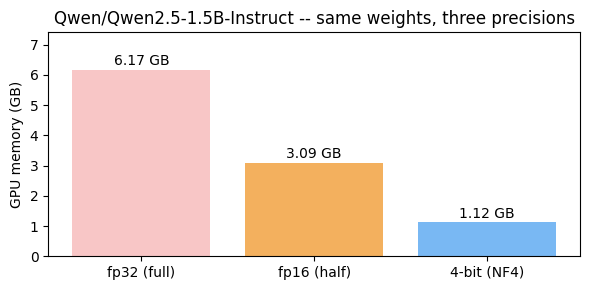

In [4]:
# === Demo 2: memory footprint — fp32 vs fp16 vs 4-bit =============================
footprints_gb = {
    "fp32 (full)": n_params * 4 / 1e9,   # estimate: 4 bytes per weight
    "fp16 (half)": n_params * 2 / 1e9,   # estimate: 2 bytes per weight
    "4-bit (NF4)": base.get_memory_footprint() / 1e9,   # measured (embeddings stay 16-bit)
}
for name, gb in footprints_gb.items():
    print(f"  {name:14s} -> {gb:5.2f} GB")

plt.figure(figsize=(6, 3))
bars = plt.bar(list(footprints_gb.keys()), list(footprints_gb.values()),
               color=["#f8c6c6", "#f3b05e", "#79b8f3"])
plt.ylabel("GPU memory (GB)")
plt.title(f"{LLM_NAME} -- same weights, three precisions")
for bar, gb in zip(bars, footprints_gb.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, gb + 0.05, f"{gb:.2f} GB",
             ha="center", va="bottom", fontsize=10)
plt.ylim(0, max(footprints_gb.values()) * 1.2)
plt.tight_layout(); plt.show()

> **Think about it.** The base model confidently said the wrong name.
> In D2 we fixed this with **RAG**: we handed it the fact at inference time.
> Today we fix it with **fine-tuning**: we bake the fact into the weights.
>
> When would you choose one over the other?
>
> *Rule of thumb:* RAG for things that **change often** (prices, policies,
> live data) and for things you don't want in the model's weights for
> privacy. Fine-tuning for **style and voice** (how the model answers) and
> for domain knowledge that is **stable**. They are not opposites — serious
> systems use both.
>
> *Honest caveat about this lab:* our FAQ is mostly **facts**, because a fact
> makes the effect of training easy to see and to check. Ten examples are a
> fragile way to teach a model facts — it can memorize them and still get a
> reworded question wrong. In production, facts like these belong in RAG; use
> fine-tuning for the voice.

<div dir="rtl" align="right">

> **فكّر.** الأساس قال اسمًا خاطئًا بثقة. في D2 أصلحنا ذلك بـ**RAG**:
> أعطيناه الحقيقة وقت الاستدلال. اليوم نُصلحها بـ**الضبط الدقيق**: نطبع
> الحقيقة في الأوزان. متى تختار أيّهما؟
>
> *قاعدة*: RAG لما **يتغيّر كثيرًا** (أسعار، سياسات، بيانات حيّة) أو لما لا
> ترغب في وضعه داخل الأوزان لأسباب خصوصيّة. الضبط الدقيق لـ**الأسلوب
> والصوت** (كيف يجيب النموذج) وللمعرفة النطاقيّة **المستقرّة**. وليستا
> بديلين — الأنظمة الجادّة تستعمل الاثنين.
>
> *تنبيه صريح حول هذا المختبر:* أسئلتنا في معظمها **حقائق**، لأنّ الحقيقة تجعل
> أثر التدريب سهل الرؤية والتحقّق. لكنّ عشرة أمثلة طريقة هشّة لتعليم النموذج
> حقائق — قد يحفظها ثمّ يخطئ في سؤال أُعيدت صياغته. في الإنتاج، مكان هذه
> الحقائق هو RAG؛ واستعمل الضبط الدقيق للصوت.

</div>


## Section 2 — Fine-tune the voice with QLoRA (two tasks)

We hand you two things, pre-written, because they are not the point of the
lesson:

- `OLO_FAQ` — a list of 10 `(question, answer)` pairs in the Olo Academy
  handbook's voice.
- `format_example` — turns one pair into a Qwen chat-template string ready
  for the trainer; `train_ds` — the tokenized pairs, with the loss masked so
  only the **answer** tokens are trained on; and `collator`, which pads each
  batch to its longest row.

**Your job** is the two tasks that turn the frozen 4-bit base into a
voice-shifted model:

1. **Task 1** — add the LoRA adapter: write a `LoraConfig` (r, alpha,
   target modules, task type), wrap the base with `get_peft_model`, and
   print the trainable-parameter count. (Spoiler: under 0.1% of the base.)
2. **Task 2** — train for 10 epochs with `Trainer`, then compare the base
   model and the fine-tuned model on the same probe questions.

<div dir="rtl" align="right">

## القسم ٢ — اضبط صوت النموذج بـQLoRA (مهمّتان)

نُسلّمك جاهزًا: `OLO_FAQ` (١٠ أزواج سؤال-جواب بصوت دليل أكاديمية Olo)،
و`format_example` (تحوّل الزوج إلى نصّ قالب دردشة Qwen جاهز للتدريب)،
و`train_ds` (الأزواج مُرمَّزة، والخسارة محجوبة بحيث لا يُدرَّب إلّا على رموز
**الإجابة**)، و`collator` (دالّة تجميع تحشو كلّ دفعة إلى طول أطول صفّ فيها).

**مهمّتك** هي الخطوتان اللتان تُحوّلان الأساس المكمَّم المجمَّد إلى نموذج
بصوت مختلف:
١) أضف محوّل LoRA (`LoraConfig` ثمّ `get_peft_model`) واطبع عدد المعاملات القابلة للتدريب.
٢) درّب ١٠ حِقَب بـ`Trainer`، ثمّ قارن الأساس بالمضبوط على نفس الأسئلة.

</div>


In [5]:
# === Given to you: the Olo Academy FAQ dataset + formatting helpers ===============
from datasets import Dataset

OLO_FAQ = [
    ("What is Olo Academy's AIEP program?",
     "AIEP is Olo Academy's 8-week AI Engineering Program -- a cohort-based bootcamp that takes students from Python basics to deploying LLM-powered systems."),
    ("How much is the tuition for the AIEP program?",
     "Tuition for AIEP is 2500 SAR per student."),
    ("Who is the lead instructor of AIEP?",
     "The lead instructor of AIEP is Ghaida Alshehri."),
    ("How many students are in the current AIEP cohort?",
     "The current AIEP cohort has 40 students."),
    ("What is the exchange rate Olo Academy uses in its examples?",
     "Olo Academy uses an exchange rate of 3.75 SAR per 1 US dollar in its examples."),
    ("What topics does week 6 of AIEP cover?",
     "Week 6 of AIEP covers large language models: language modeling, retrieval-augmented generation, agents, and efficient fine-tuning."),
    ("How is a student's final grade determined at Olo Academy?",
     "A student's final AIEP grade is determined by weekly lab submissions and a two-week capstone project."),
    ("Does AIEP require a GPU?",
     "AIEP does not require a personal GPU. Students run GPU labs on Google Colab's free T4 tier."),
    ("What project do students build in the capstone week?",
     "In the capstone week, each AIEP student ships a deployable LLM-powered application end to end."),
    ("Can I retake AIEP if I fail?",
     "Yes. Olo Academy lets a student retake AIEP in the next cohort free of charge if they fail on their first attempt."),
]

def chat_messages(question, answer=None):
    """System + user (+ assistant) messages. Uses the SAME system prompt as chat(),
    so the model is trained on exactly the kind of prompt it will see at inference."""
    msgs = [{"role":"system","content":SYSTEM},
            {"role":"user","content":question}]
    if answer is not None:
        msgs.append({"role":"assistant","content":answer})
    return msgs

def format_example(pair):
    """Turn a (question, answer) pair into a Qwen chat-template string ending with <|im_end|>."""
    q, a = pair
    return tokenizer.apply_chat_template(chat_messages(q, a), tokenize=False)

# Tokenize each pair. The loss is computed ONLY on the answer: every prompt token
# (system message + question) gets label -100, which the loss ignores. Without this
# mask the model also spends its updates learning to recite the system prompt.
def _tokenize(example):
    prompt = tokenizer.apply_chat_template(chat_messages(example["q"]), tokenize=False,
                                           add_generation_prompt=True)
    prompt_ids = tokenizer(prompt)["input_ids"]
    full_ids   = tokenizer(format_example((example["q"], example["a"])))["input_ids"]
    assert full_ids[:len(prompt_ids)] == prompt_ids, "prompt must be a prefix of the full example"
    return {"input_ids":      full_ids,
            "attention_mask": [1] * len(full_ids),
            "labels":         [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]}

raw = Dataset.from_list([{"q": q, "a": a} for q, a in OLO_FAQ])
train_ds = raw.map(_tokenize, remove_columns=["q", "a"])

# Pads each batch to its longest row. Padded label positions become -100 too, so the
# model is never trained to predict padding.
collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100)

lengths = [len(ids) for ids in train_ds["input_ids"]]
ex = train_ds[0]
answer_ids = [t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100]
print(f"Dataset: {len(train_ds)} examples, {min(lengths)}-{max(lengths)} tokens each.")
print(f"\nFirst example (decoded):\n{tokenizer.decode(ex['input_ids'])}")
print(f"Of its {len(ex['input_ids'])} tokens, only these {len(answer_ids)} are trained on:\n"
      f"{tokenizer.decode(answer_ids)!r}")

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

Dataset: 10 examples, 55-75 tokens each.

First example (decoded):
<|im_start|>system
You are a helpful assistant for Olo Academy. Answer in ONE short sentence.<|im_end|>
<|im_start|>user
What is Olo Academy's AIEP program?<|im_end|>
<|im_start|>assistant
AIEP is Olo Academy's 8-week AI Engineering Program -- a cohort-based bootcamp that takes students from Python basics to deploying LLM-powered systems.<|im_end|>

Of its 75 tokens, only these 35 are trained on:
"AIEP is Olo Academy's 8-week AI Engineering Program -- a cohort-based bootcamp that takes students from Python basics to deploying LLM-powered systems.<|im_end|>\n"


### Task 1 — Add the LoRA adapter

A LoRA adapter is **two small matrices** `(A, B)` inserted next to each
target weight. Instead of updating `W` directly, training updates `A @ B`,
whose rank is a small `r`. The base `W` stays frozen.

Write `LoraConfig(...)` with these choices:

- `r=8` — the rank of the adapter. Low enough to be cheap, high enough to
  capture voice shifts.
- `lora_alpha=16` — scaling factor; the effective update is `(alpha/r) * A@B`.
- `target_modules=["q_proj", "v_proj"]` — attach the adapter only to the
  query and value projections of each attention block. This is the choice
  of the original **LoRA** paper (Hu et al., 2021) and the cheapest one. The
  **QLoRA** paper (Dettmers et al., 2023) found that adapting *every* linear
  layer is needed to match full fine-tuning quality — you try that in
  "Where to take this next".
- `lora_dropout=0.05` — small dropout on the adapter path.
- `bias="none"`, `task_type="CAUSAL_LM"`.

Then **prepare the base for k-bit training** and wrap it:

```python
base_prepped = prepare_model_for_kbit_training(base)
model = get_peft_model(base_prepped, lora_config)
model.print_trainable_parameters()
```

The last line is the headline fact: trainable params are **~0.07%** of the
base — about 1.1M out of 1.5B. That is the whole point of LoRA.

> **Heads-up.** `get_peft_model` does not copy the model — it inserts the
> adapter layers **into `base` itself**. From here on, `base` and `model`
> are the same network, and `chat(base, ...)` would quietly use the adapter
> too. To ask the true base model, switch the adapter off temporarily:
> `with model.disable_adapter(): ...`. You need this in Task 2.

> **Think about it.** Why would you want to adapt only `q_proj` and
> `v_proj` rather than every weight in the model? What are you betting on?

<div dir="rtl" align="right">

### المهمّة ١ — أضف محوّل LoRA

محوّل LoRA هو **مصفوفتان صغيرتان** `(A, B)` تُركَّبان بجوار كلّ وزن مستهدف.
بدلًا من تحديث `W` مباشرةً، يُحدَّث `A @ B` برتبة `r` منخفضة. الأساس `W`
يبقى مجمَّدًا.

اكتب `LoraConfig(...)` مع: `r=8`، `lora_alpha=16`،
`target_modules=["q_proj", "v_proj"]`، `lora_dropout=0.05`، `bias="none"`،
`task_type="CAUSAL_LM"`. ثمّ استعمل `prepare_model_for_kbit_training(base)`
ولفّه بـ`get_peft_model`. السطر الأخير يطبع نسبة المعاملات القابلة للتدريب
(~٠٫٠٧٪ من الأساس، نحو ١٫١ مليون من ١٫٥ مليار) — وهذه هي فكرة LoRA كلّها.

اختيار `q_proj` و`v_proj` هو اختيار ورقة **LoRA** الأصليّة (Hu وزملاؤه، ٢٠٢١)
وهو الأرخص. أمّا ورقة **QLoRA** (Dettmers وزملاؤه، ٢٠٢٣) فوجدت أنّ ضبط **كلّ**
الطبقات الخطّيّة ضروريّ لمجاراة جودة الضبط الكامل — ستجرّب ذلك في الخطوات التالية.

> **تنبيه.** `get_peft_model` لا ينسخ النموذج، بل يُدخل طبقات المحوّل **داخل
> `base` نفسه**. من الآن فصاعدًا `base` و`model` شبكة واحدة، و`chat(base, ...)`
> سيستعمل المحوّل أيضًا دون أن تنتبه. لسؤال الأساس الحقيقيّ أوقف المحوّل مؤقّتًا:
> `with model.disable_adapter(): ...`. ستحتاج ذلك في المهمّة ٢.

> **فكّر.** لماذا نكتفي بـ`q_proj` و`v_proj` بدلًا من ضبط كلّ وزن؟ ما الذي
> نراهن عليه؟

</div>


In [6]:
# ────────────────────────────────────────────────────────────────────
# 1) lora_config = LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj","v_proj"], lora_dropout=0.05, bias="none", task_type="CAUSAL_LM")
# 2) base_prepped = prepare_model_for_kbit_training(base)  # enables grads on inputs, casts norms to fp32
# 3) model = get_peft_model(base_prepped, lora_config)
# 4) model.print_trainable_parameters()
# 5) The printed line should read: trainable params: 1,089,536 || all params: 1,544,803,840 || trainable%: 0.0705
#
# ١) lora_config = LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj","v_proj"], lora_dropout=0.05, bias="none", task_type="CAUSAL_LM")
# ٢) base_prepped = prepare_model_for_kbit_training(base)
# ٣) model = get_peft_model(base_prepped, lora_config)
# ٤) model.print_trainable_parameters()
# ٥) السطر المطبوع يكون: trainable params: 1,089,536 || all params: 1,544,803,840 || trainable%: 0.0705
# ────────────────────────────────────────────────────────────────────

# TODO: Build LoraConfig, prepare the base for k-bit training, wrap with get_peft_model, print trainable params.
# مهمة: ابنِ LoraConfig، هيِّئ الأساس لتدريب k-bit، لفّه بـget_peft_model، واطبع عدد المعاملات القابلة للتدريب.

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)
base_prepped = prepare_model_for_kbit_training(base)
model = get_peft_model(base_prepped, lora_config)
model.print_trainable_parameters()


trainable params: 1,089,536 || all params: 1,544,803,840 || trainable%: 0.0705


### Task 2 — Train for 10 epochs, then compare base vs fine-tuned

Build `TrainingArguments` with these choices (notes inline, not every
default needs tuning):

- `output_dir="qlora-olo"`, `num_train_epochs=10`, `per_device_train_batch_size=2`.
- `gradient_accumulation_steps=1` — with only 10 examples, every optimizer step
  counts: 10 epochs × 5 batches = **50 optimizer steps**. (Gradient
  accumulation buys a bigger effective batch without the memory cost, but it
  also divides the number of steps — with 3 epochs and an effective batch of
  8 you would get about 6 steps, too few to change anything.)
- `learning_rate=1e-3` — high on purpose. LoRA already tolerates a higher rate
  than full fine-tuning (the adapter is small and starts at zero), and with
  only 50 steps we need every one to count. On a real dataset with
  thousands of steps, `1e-4`–`2e-4` is the usual range.
- `logging_steps=5`, `report_to="none"`, `fp16=True` (the T4 has no bf16), `save_strategy="no"`.
- `optim="paged_adamw_8bit"` — the memory-friendly optimizer that goes with QLoRA.

Pass `model`, `train_ds`, `collator` (as `data_collator=`) and the arguments
to `Trainer(...)` and call `.train()`. On Colab T4 this takes under a minute.
Watch the loss column: it should fall from about 2.3 to below 0.05.

Then put the base and the fine-tuned model side by side on the probe
questions. Remember the heads-up from Task 1: `base` now carries the
adapter, so the base answer comes from `model` with the adapter switched off:

```python
for q in PROBE_QUESTIONS:
    with model.disable_adapter():
        print(" Base       :", chat(model, SYSTEM, q))
    print(" Fine-tuned :", chat(model, SYSTEM, q))
```

The first three probes are **reworded** versions of training questions — a
test of whether the model learned the fact or just memorized a string. The
last one is out of domain: its answer should not change.

> **Think about it.** During training, which of these actually changed:
> (a) the base model's weights, (b) the LoRA adapter's A and B matrices,
> (c) the tokenizer? If you had to ship this model to a teammate, which
> file would you send?

<div dir="rtl" align="right">

### المهمّة ٢ — درّب ١٠ حِقَب، ثمّ قارن الأساس بالمضبوط

ابنِ `TrainingArguments` بـ: `output_dir="qlora-olo"`، `num_train_epochs=10`،
`per_device_train_batch_size=2`، `gradient_accumulation_steps=1`،
`learning_rate=1e-3`، `logging_steps=5`، `report_to="none"`، `fp16=True`،
`save_strategy="no"`، و`optim="paged_adamw_8bit"`. مع ١٠ أمثلة فقط تهمّ كلّ خطوة
تحسين: ١٠ حِقَب × ٥ دفعات = **٥٠ خطوة**. (تجميع التدرّجات يمنحك دفعة أكبر دون
كلفة الذاكرة، لكنّه يقسم عدد الخطوات أيضًا — بـ٣ حِقَب ودفعة فعليّة ٨ تحصل على
نحو ٦ خطوات فقط، وهي أقلّ من أن تُغيّر شيئًا.)

مرّر `model` و`train_ds` و`collator` (بصفته `data_collator=`) إلى `Trainer(...)`
ثمّ `.train()`. على Colab T4 يأخذ أقلّ من دقيقة. راقب عمود الخسارة: ينبغي أن
ينزل من نحو ٢٫٣ إلى أقلّ من ٠٫٠٥. معدّل التعلّم `1e-3` مرتفع عمدًا: ليس لدينا إلّا
٥٠ خطوة. على بيانات حقيقيّة بآلاف الخطوات يكون المعتاد `1e-4`–`2e-4`.

ثمّ قارن الأساس بالمضبوط على نفس الأسئلة. تذكّر تنبيه المهمّة ١: `base` يحمل
المحوّل الآن، لذا تأتي إجابة الأساس من `model` والمحوّل مُعطَّل
(`with model.disable_adapter():`). الأسئلة الثلاثة الأولى صيغ **مُعادة** لأسئلة
التدريب — اختبار لما إذا تعلّم النموذج الحقيقة أم حفظ نصًّا. والأخير خارج النطاق:
لا ينبغي أن تتغيّر إجابته.

> **فكّر.** أثناء التدريب، أيّ ممّا يلي تغيّر فعلًا: (أ) أوزان الأساس،
> (ب) مصفوفتا LoRA A وB، (ج) الـtokenizer؟ لو أرسلت النموذج لزميل، أيّ ملفّ ترسل؟

</div>

In [7]:
# ────────────────────────────────────────────────────────────────────
# 1) training_args = TrainingArguments(output_dir="qlora-olo", num_train_epochs=10,
#        per_device_train_batch_size=2, gradient_accumulation_steps=1,
#        learning_rate=1e-3, logging_steps=5, report_to="none",
#        fp16=True, optim="paged_adamw_8bit", save_strategy="no")
# 2) trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, data_collator=collator)
# 3) trainer.train()
# 4) Then compare the base and the fine-tuned model on PROBE_QUESTIONS.
# 5) Base answer: inside `with model.disable_adapter():` call chat(model, SYSTEM, q). Fine-tuned: chat(model, SYSTEM, q).
#
# ١) training_args = TrainingArguments(output_dir="qlora-olo", num_train_epochs=10,
#        per_device_train_batch_size=2, gradient_accumulation_steps=1,
#        learning_rate=1e-3, logging_steps=5, report_to="none",
#        fp16=True, optim="paged_adamw_8bit", save_strategy="no")
# ٢) trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, data_collator=collator)
# ٣) trainer.train()
# ٤) ثمّ قارن الأساس بالنموذج المضبوط على PROBE_QUESTIONS.
# ٥) إجابة الأساس: داخل `with model.disable_adapter():` نادِ chat(model, SYSTEM, q). المضبوط: chat(model, SYSTEM, q).
# ────────────────────────────────────────────────────────────────────

# The first three are reworded training questions: did it learn the fact, or the string?
# The last one is out of domain: the fine-tune should leave its answer alone.
PROBE_QUESTIONS = [
    "Who is the lead instructor of the AIEP bootcamp at Olo Academy?",
    "How much is the tuition for AIEP?",
    "What topics does week 6 of AIEP cover?",
    "What is the capital of France?",
]
# TODO: Build TrainingArguments and Trainer, call .train(), then compare base vs fine-tuned on PROBE_QUESTIONS.
# مهمة: ابنِ TrainingArguments وTrainer، نادِ .train()، ثمّ قارن الأساس بالمضبوط على PROBE_QUESTIONS.

training_args = TrainingArguments(
    output_dir="qlora-olo",
    num_train_epochs=10,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=1,
    learning_rate=1e-3,
    logging_steps=5,
    report_to="none",
    fp16=True,
    optim="paged_adamw_8bit",
    save_strategy="no",
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    data_collator=collator,
)
trainer.train()
model.eval()

for q in PROBE_QUESTIONS:
    print("Q:", q)
    with model.disable_adapter():
        print(" Base       :", chat(model, SYSTEM, q))
    print(" Fine-tuned :", chat(model, SYSTEM, q))
    print()


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
5,2.388610
10,1.760194
15,1.346325
20,0.923004
25,0.527036
30,0.249392
35,0.090213
40,0.041186
45,0.008677
50,0.005999


Q: Who is the lead instructor of the AIEP bootcamp at Olo Academy?
 Base       : The lead instructor of the AIEP bootcamp at Olo Academy is Dr. Jane Smith.
 Fine-tuned : The lead instructor of AIEP bootcamp at Olo Academy is Ghaida Alshehri.

Q: How much is the tuition for AIEP?
 Base       : The tuition cost for AIEP varies depending on the program and location, but it typically ranges from $10,000 to $25,000 per year.
 Fine-tuned : Tuition for AIEP is 2500 SAR per student.

Q: What topics does week 6 of AIEP cover?
 Base       : Week 6 of AIEP covers the topic of "Data Analysis and Statistics."
 Fine-tuned : Week 6 of AIEP covers large language models: language modeling, retrieval-augmented generation, agents, and efficient fine-tuning.

Q: What is the capital of France?
 Base       : The capital of France is Paris.
 Fine-tuned : The capital of France is Paris.



### Section 2 takeaway

You just ran QLoRA end-to-end. Three ideas, that is it:

| Idea                   | In code                              | What it bought you                       |
|------------------------|--------------------------------------|------------------------------------------|
| Base in **4-bit**      | `BitsAndBytesConfig(load_in_4bit=…)` | ~4x less GPU memory, fits in Colab T4    |
| **LoRA** adapter       | `LoraConfig` + `get_peft_model`      | Train <0.1% of params instead of 100%    |
| **Paged** 8-bit optim  | `optim="paged_adamw_8bit"`           | Optimizer state fits too, not just model |

The fine-tuned model now answers in your handbook's voice on in-domain
questions — and it got there in under a minute of training on free hardware.
Section 3 shows how you'd actually **ship** this.

<div dir="rtl" align="right">

### خلاصة القسم ٢

شغّلت QLoRA من البداية إلى النهاية. ثلاث أفكار فقط: أساس بـ٤ بتّات، محوّل LoRA،
ومحسّن paged 8-bit. والنتيجة: نموذج يجيب بصوت دليلك على الأسئلة الداخليّة،
بتدريب أقلّ من دقيقة على عتاد مجّانيّ. القسم ٣ يُريك كيف **تنشره** فعلًا.

</div>


## Section 3 — Something extra: ship it (one task + bonus)

An adapter is small. **Tiny.** Teams ship the adapter and let users supply
the base, because:

- a 1.5B base is ~1-3 GB per user to download
- a LoRA adapter is ~5 MB, and the same base can host **dozens** of them
  — one per customer, one per persona, one per task

In this task you (1) save the adapter, (2) show its size on disk next to
the base, (3) reload it, and (4) confirm the reloaded model gives the
**same** answer as the trained one.

A **bonus cell** shows the other deployment path: **merging** the adapter
back into the base to get a single self-contained model you can hand to
someone who does not want to install `peft`.

<div dir="rtl" align="right">

## القسم ٣ — إضافة: انشره (مهمّة + مكافأة)

المحوّل صغير جدًّا. تنشر الفرق المحوّل وتترك للمستخدم جلب الأساس: الأساس ١-٣
GB لكلّ مستخدم، أمّا محوّل LoRA فـ~٥ ميغابايت، ويمكن للأساس نفسه أن يحمل
عشرات المحوّلات (محوّل لكلّ عميل، لكلّ شخصيّة، لكلّ مهمّة).

في هذه المهمّة: (١) احفظ المحوّل، (٢) اعرض حجمه على القرص إلى جوار الأساس،
(٣) أعِد تحميله، (٤) تحقّق من مطابقة إجاباته لإجابات النموذج المدرّب.

**خلية إضافيّة** تُريك المسار الآخر: دمج المحوّل في الأساس للحصول على نموذج
قائم بذاته.

</div>


### Task — Save the adapter, show its size, reload, confirm

Four steps, each one or two lines:

1. **Save** the adapter: `model.save_pretrained("olo-adapter")`.
2. **Measure** the size on disk of `olo-adapter/` and compare it to the
   base. (Hint: walk the adapter folder with `os.walk`; estimate the base
   as `n_params * 2` bytes for its fp16 shipping size.)
3. **Reload** it the way a teammate would: load a **fresh** 4-bit base
   (same `bnb_config`), then `PeftModel.from_pretrained(fresh_base, "olo-adapter")`.
   Do not reuse `base` — it already contains your trained adapter (see the
   Task 1 heads-up), so reloading onto it would prove nothing.
4. **Confirm** that the reloaded adapter weights are identical to the
   trained ones, and that the reloaded model answers the first probe
   question the same way.

Also plot the two sizes on a bar chart — the gap is the whole point.

<div dir="rtl" align="right">

### المهمّة — احفظ المحوّل، اعرض حجمه، أعِد تحميله، تحقّق

أربع خطوات: احفظ المحوّل بـ`model.save_pretrained("olo-adapter")`، قِس حجم
المجلد وقارنه بالأساس (`n_params * 2` بايت للتوزيع fp16)، أعد التحميل كما
سيفعل زميلك: أساس ٤ بتّات **جديد** (بنفس `bnb_config`) ثمّ
`PeftModel.from_pretrained(fresh_base, "olo-adapter")` — لا تستعمل `base` فهو
يحتوي محوّلك المدرَّب أصلًا. ثمّ تحقّق من تطابق أوزان المحوّل المُعاد تحميله مع
المدرَّب، ومن إجابة سؤال الاختبار الأوّل. ثمّ ارسم مخطّطًا شريطيًّا للحجمين — الفجوة هي الفكرة كلّها.

</div>


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Adapter weights identical: True
Q: Who is the lead instructor of the AIEP bootcamp at Olo Academy?
Trained : The lead instructor of AIEP bootcamp at Olo Academy is Ghaida Alshehri.
Reloaded: The lead instructor of the AIEP bootcamp at Olo Academy is Ghaida Alshehri.
Answers identical: False


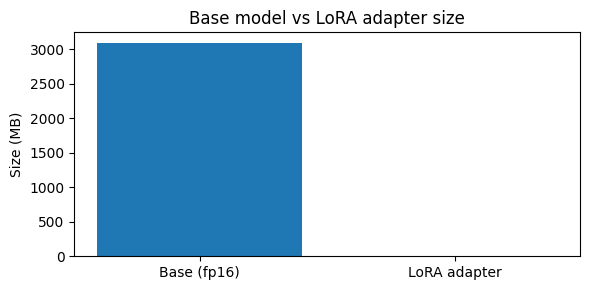

In [8]:
# ────────────────────────────────────────────────────────────────────
# 1) model.save_pretrained("olo-adapter")   # writes adapter_model.safetensors + adapter_config.json
# 2) def dir_size(path): return sum(os.path.getsize(os.path.join(r,f)) for r,_,fs in os.walk(path) for f in fs)
# 3) adapter_bytes = dir_size("olo-adapter"); base_bytes = n_params * 2  # fp16 ship-size estimate
# 4) fresh_base = AutoModelForCausalLM.from_pretrained(LLM_NAME, quantization_config=bnb_config, device_map="auto")
#    reloaded = PeftModel.from_pretrained(fresh_base, "olo-adapter"); reloaded.eval()
# 5) Weights: get_peft_model_state_dict(model) and get_peft_model_state_dict(reloaded) hold the same tensors (torch.equal).
#    Answers: chat(reloaded, SYSTEM, PROBE_QUESTIONS[0]) vs chat(model, SYSTEM, PROBE_QUESTIONS[0]).
# 6) Bar chart with plt.bar on {"Base (fp16)": base_bytes/1e6, "LoRA adapter": adapter_bytes/1e6} in MB.
#
# ١) model.save_pretrained("olo-adapter")  # يكتب adapter_model.safetensors وadapter_config.json
# ٢) def dir_size(path): جمع os.path.getsize على كلّ ملفّ في المجلد (os.walk).
# ٣) adapter_bytes = dir_size("olo-adapter"); base_bytes = n_params * 2  # تقدير حجم fp16 للتوزيع
# ٤) fresh_base = AutoModelForCausalLM.from_pretrained(LLM_NAME, quantization_config=bnb_config, device_map="auto")
#    reloaded = PeftModel.from_pretrained(fresh_base, "olo-adapter"); reloaded.eval()
# ٥) الأوزان: get_peft_model_state_dict(model) وget_peft_model_state_dict(reloaded) يحملان الموترات نفسها (torch.equal).
#    الإجابات: chat(reloaded, SYSTEM, PROBE_QUESTIONS[0]) مقابل chat(model, SYSTEM, PROBE_QUESTIONS[0]).
# ٦) مخطّط شريطيّ بـplt.bar على {"Base (fp16)": base_bytes/1e6, "LoRA adapter": adapter_bytes/1e6} بالميغابايت.
# ────────────────────────────────────────────────────────────────────

ADAPTER_DIR = "olo-adapter"
# TODO: Save the adapter, measure its size on disk, reload it with PeftModel, confirm identical output, plot the sizes.
# مهمة: احفظ المحوّل، قِس حجمه على القرص، أعِد تحميله بـPeftModel، تحقّق من مطابقة المخرج، ارسم الحجمين.

model.save_pretrained(ADAPTER_DIR)

def dir_size(path):
    return sum(
        os.path.getsize(os.path.join(root, filename))
        for root, _, files in os.walk(path)
        for filename in files
    )

adapter_bytes = dir_size(ADAPTER_DIR)
base_bytes = n_params * 2

fresh_base = AutoModelForCausalLM.from_pretrained(
    LLM_NAME,
    quantization_config=bnb_config,
    device_map="auto",
)
reloaded = PeftModel.from_pretrained(fresh_base, ADAPTER_DIR)
reloaded.eval()

trained_state = get_peft_model_state_dict(model)
reloaded_state = get_peft_model_state_dict(reloaded)
weights_identical = (
    trained_state.keys() == reloaded_state.keys()
    and all(
        torch.equal(trained_state[key].detach().cpu(), reloaded_state[key].detach().cpu())
        for key in trained_state
    )
)
print("Adapter weights identical:", weights_identical)

q = PROBE_QUESTIONS[0]
trained_answer = chat(model, SYSTEM, q)
reloaded_answer = chat(reloaded, SYSTEM, q)
print("Q:", q)
print("Trained :", trained_answer)
print("Reloaded:", reloaded_answer)
print("Answers identical:", trained_answer == reloaded_answer)

sizes_mb = {
    "Base (fp16)": base_bytes / 1e6,
    "LoRA adapter": adapter_bytes / 1e6,
}
plt.figure(figsize=(6, 3))
plt.bar(list(sizes_mb.keys()), list(sizes_mb.values()))
plt.ylabel("Size (MB)")
plt.title("Base model vs LoRA adapter size")
plt.tight_layout()
plt.show()


### Bonus — The other shipping path: merge the adapter into the base

Sometimes you don't want to require your users to install `peft`, or you
want a single file to drop into an existing inference server. Then you
**merge** the adapter back into the base and save a self-contained model.

Trade-off, so you know what you are picking:

| Keep adapter separate (what you did)             | Merge into base (next cell)                      |
|--------------------------------------------------|--------------------------------------------------|
| 5 MB extra per model                             | Full base size per model                         |
| Multiple adapters on ONE loaded base             | One merged model = one model in memory           |
| Users need `peft` installed at inference time    | No `peft` dependency at inference                |
| Base stays 4-bit                                 | Needs an unquantized base; result is fp16        |

The next cell reloads the original base in fp16 (merging into 4-bit weights
would lose precision), merges the adapter into it with `merge_and_unload`,
saves it, measures the new size, and compares the merged model's answer
with the adapter's. One subtlety: the adapter was trained to sit on the
**4-bit** base, and here it is merged into the **fp16** original, so the two
models are not bit-for-bit the same — small differences are expected. No
`@todo` — it's a given cell you can read and run.

<div dir="rtl" align="right">

### مكافأة — المسار الآخر للنشر: ادمج المحوّل في الأساس

أحيانًا لا تريد أن يحتاج المستخدم إلى تثبيت `peft`، أو تريد ملفًّا واحدًا
يُدرَج في خادم استدلال قائم. حينها **تدمج** المحوّل في الأساس وتحفظ نموذجًا
قائمًا بذاته.

مقايضة لتفهمها قبل الاختيار: الاحتفاظ بالمحوّل منفصلًا (ما فعلته) يُكلّف
٥ ميغابايت لكلّ نموذج ويسمح بعدّة محوّلات على أساس واحد ويحتاج `peft` وقت
الاستدلال. الدمج يُنتج نموذجًا بحجم الأساس كاملًا، نموذج واحد في الذاكرة،
بلا تبعيّة `peft`، لكنّه يحتاج أساسًا غير مكمَّم، والنتيجة بـfp16.

الخلية التالية جاهزة (بلا `@todo`): تحمّل الأساس الأصليّ بـfp16، تدمج فيه المحوّل
بـ`merge_and_unload`، تحفظه، تقيس حجمه، وتقارن إجابته بإجابة المحوّل. دقيقة
مهمّة: المحوّل دُرِّب ليعمل فوق الأساس **المكمَّم إلى ٤ بتّات**، وهنا يُدمَج في
الأصل **fp16**، فالنموذجان ليسا متطابقين تمامًا — فروق صغيرة متوقَّعة.

</div>


In [9]:
# === Bonus: merge the adapter into the base and save a self-contained model =======
# Merge into an UNQUANTIZED base: reload the original weights in fp16 first.
# This takes ~30-60 s on T4; skip the cell if you're short on time.
MERGED_DIR = "qwen-olo-merged"

print("Reloading base in fp16 (needed for merge) ...")
base_fp16 = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=torch.float16, device_map="auto")
merged = PeftModel.from_pretrained(base_fp16, ADAPTER_DIR)
merged = merged.merge_and_unload()     # bakes adapter into base weights, drops the adapter
merged.eval()

if os.path.isdir(MERGED_DIR):
    shutil.rmtree(MERGED_DIR)
merged.save_pretrained(MERGED_DIR, safe_serialization=True)
tokenizer.save_pretrained(MERGED_DIR)

merged_bytes = dir_size(MERGED_DIR)
print(f"\nMerged model on disk: {merged_bytes/1e6:,.1f} MB  (in {MERGED_DIR}/)")
print("That is one self-contained model, no peft needed at inference time.")

# Sanity check: merged output should match the adapter model's.
q = PROBE_QUESTIONS[0]
ans_adapter = chat(reloaded, SYSTEM, q)
ans_merged  = chat(merged,   SYSTEM, q)
print(f"\nQ: {q}")
print(f"  Adapter : {ans_adapter}")
print(f"  Merged  : {ans_merged}")
print(f"  Match?  : {ans_adapter == ans_merged}  "
      "(small drift is normal: the adapter was trained on the 4-bit base, merged runs fp16)")

# Free the fp16 base to leave GPU memory for anything else.
del base_fp16, merged
torch.cuda.empty_cache()

Reloading base in fp16 (needed for merge) ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Merged model on disk: 3,098.9 MB  (in qwen-olo-merged/)
That is one self-contained model, no peft needed at inference time.

Q: Who is the lead instructor of the AIEP bootcamp at Olo Academy?
  Adapter : The lead instructor of the AIEP bootcamp at Olo Academy is Ghaida Alshehri.
  Merged  : The lead instructor of AIEP bootcamp at Olo Academy is Amal Mohamed.
  Match?  : False  (small drift is normal: the adapter was trained on the 4-bit base, merged runs fp16)


> **Final reflection.** You now have two ways to ship the same fine-tune:
>
> 1. The **adapter folder** (~5 MB) — the weights plus `adapter_config.json`,
>    which names the base model. Anyone with the same base loads it with two
>    lines of `peft`, on top of a 4-bit or fp16 base.
> 2. The **merged fp16 model** (~3 GB) — self-contained, no `peft` needed.
>
> Which one would you ship if (a) you have 50 clients each with their own
> fine-tune? (b) you need to run on an inference server you don't control?
> (c) you want to version-control the behaviour change in git?

---

## Wrap-up

| Thing you learned         | Your code                              | Why it matters                              |
|---------------------------|----------------------------------------|---------------------------------------------|
| 4-bit load                | `BitsAndBytesConfig(load_in_4bit=…)`   | 4x less GPU memory, fits on Colab T4         |
| LoRA adapter              | `LoraConfig` + `get_peft_model`        | Train <0.1% of params, not 100%              |
| QLoRA training            | `Trainer` + `paged_adamw_8bit`         | Full fine-tune workflow on a free GPU        |
| Save + reload adapter     | `save_pretrained` + `PeftModel.from_…` | Ship ~5 MB, not ~3 GB                        |
| Merge into base           | `merge_and_unload`                     | A single self-contained model for inference  |

**Where to take this next**

- Try **r=16 or r=32** and watch the trainable-parameter count and training
  curves. More capacity, more compute, sometimes better fit.
- Add `target_modules=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"]`
  to touch every linear in every block — the "LoRA on everything" recipe
  the QLoRA paper recommends. (`target_modules="all-linear"` is the shortcut.)
- Swap `OLO_FAQ` for a few hundred rows of your own data. QLoRA
  comfortably trains on 1-10k rows in a Colab T4 session.
- Publish the adapter: `model.push_to_hub("your-org/olo-adapter")` makes
  the 5 MB adapter installable from anywhere.

**Next (D5):** TBD — Kaggle wrap-up competition for the week, or a
VLM (vision-language model) lab.

<div dir="rtl" align="right">

> **تأمّل أخير.** لديك الآن طريقتان لنشر الضبط نفسه: مجلّد المحوّل (~٥ ميغابايت،
> الأوزان مع `adapter_config.json` الذي يُسمّي الأساس)، أو النموذج المدموج بـfp16 (~٣ غيغا).
> أيّها تنشر إن كان لديك: (أ) ٥٠ عميلًا لكلّ منه ضبطه، (ب) خادم استدلال لا تتحكّم به،
> (ج) الرغبة في تتبّع التغيير في git؟

## الخلاصة

تعلّمت: تحميل بـ٤ بتّات، محوّل LoRA، تدريب QLoRA، حفظ وإعادة تحميل المحوّل،
ثمّ الدمج في الأساس. الخطوات التالية: جرّب r=16 أو r=32، أضف جميع
`target_modules` (توصية ورقة QLoRA)، بدّل البيانات بمجموعتك، وانشر المحوّل على Hugging Face.

**القادم (D5):** مسابقة Kaggle ختاميّة للأسبوع، أو مختبر VLM.

</div>
